# Tentativo 16 · 3. Il classificatore a feature

Il classificatore di sempre: **TF-IDF** di parole e coppie di parole (al più 100.000) su **ogni articolo**, un modello
lineare, poi si mettono insieme gli articoli di ogni testata. Stessi 5 fold del notebook 1; a ogni fold il TF-IDF e i
modelli si imparano sui soli articoli di training. Lo addestriamo in sei modi:

| | che cosa impara | su quali articoli | come si decide la testata |
|---|---|---|---|
| **1. 5 classi** | il livello (l1…l5) | tutti | voto degli articoli |
| **2. binario** | affidabile sì/no (punteggio ≥ 60) | tutti | voto degli articoli |
| **3. binario sugli estremi** | affidabile sì/no | solo l1, l2, l4, l5 | voto degli articoli |
| **4. regressione** | il punteggio 0–100 | tutti | media dei punteggi previsti |
| **5. regressione bilanciata** | il punteggio 0–100, ogni livello pesa uguale | tutti | media dei punteggi previsti |
| **6. regressione sugli estremi** | il punteggio 0–100 | solo l1, l2, l4, l5 | media dei punteggi previsti |

Iperparametri fissi, gli stessi per tutti: regressione logistica con C = 10 e classi bilanciate; regressione ridge con
alpha = 1.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import Parallel, delayed
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import f1_score, roc_auc_score

import funzioni as F

warnings.filterwarnings("ignore")
OUT = Path("Results/feature"); GRAFICI = OUT / "grafici"; GRAFICI.mkdir(parents=True, exist_ok=True)
GRIGIO, CHIARO = "#52514e", "#b5b3ab"
COLORE_LIVELLO = ["#b02a2a", "#ef8f8d", "#86b6ef", "#3987e5", "#1c5cab"]
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7", "axes.grid": True,
                     "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.titlelocation": "left", "legend.frameon": False})
pd.set_option("display.width", 200)

art = pd.read_csv("Results/dataset/articoli.csv.gz")
t = pd.read_csv("Results/dataset/testate.csv", index_col="domain")
print(f"{len(art):,} articoli di {len(t)} testate, 5 fold")

29,524 articoli di 233 testate, 5 fold


## 1. Addestramento: sei modelli per fold

Per ogni fold: TF-IDF sugli articoli di training, i sei modelli, la previsione di ogni articolo di test (circa 4 minuti
la prima volta; poi si ricarica).

In [2]:
# 1.1 i sei modelli, fold per fold
def un_fold(k):
    tr, te = (art.fold != k).to_numpy(), (art.fold == k).to_numpy()
    v = F._tfidf(); Xtr = v.fit_transform(art.text[tr]); Xte = v.transform(art.text[te])
    y, s = art.label.to_numpy()[tr], art.score.to_numpy()[tr]
    affidabile, estremi = y >= 2, y != 2
    bilanciati = lambda etichette: F.pesi_bilanciati(etichette, np.ones(len(etichette)))       # ogni classe pesa uguale
    out = art.loc[te, ["article_id", "domain"]].reset_index(drop=True)

    m = LogisticRegression(C=10, max_iter=2000).fit(Xtr, y, sample_weight=bilanciati(y))                     # 1. 5 classi
    P = np.zeros((te.sum(), 5)); P[:, m.classes_] = m.predict_proba(Xte); out[F.CLASSI] = P
    m = LogisticRegression(C=10, max_iter=2000).fit(Xtr, affidabile, sample_weight=bilanciati(affidabile))   # 2. binario
    out["p_binario"] = m.predict_proba(Xte)[:, 1]
    m = LogisticRegression(C=10, max_iter=2000).fit(Xtr[estremi], affidabile[estremi], sample_weight=bilanciati(affidabile[estremi]))
    out["p_binario_estremi"] = m.predict_proba(Xte)[:, 1]                                                    # 3. binario sugli estremi
    out["s_regressione"] = Ridge(alpha=1.0).fit(Xtr, s).predict(Xte)                                         # 4. regressione
    out["s_regressione_bilanciata"] = Ridge(alpha=1.0).fit(Xtr, s, sample_weight=bilanciati(y)).predict(Xte)  # 5. bilanciata
    out["s_regressione_estremi"] = Ridge(alpha=1.0).fit(Xtr[estremi], s[estremi]).predict(Xte)               # 6. sugli estremi
    return out

f = OUT / "previsioni_articoli.csv"
if f.exists():
    pa = pd.read_csv(f)
else:
    pa = pd.concat(Parallel(n_jobs=5)(delayed(un_fold)(k) for k in range(1, 6)), ignore_index=True)
    pa.to_csv(f, index=False)
print(f"{len(pa):,} articoli previsti")

29,524 articoli previsti


## 2. Dagli articoli alle testate

- **classificatori**: la testata prende il **voto di maggioranza** dei suoi articoli;
- **regressioni**: la testata prende la **media dei punteggi** previsti. I 5 livelli si ricavano con le **quote del
  training** (le testate si ordinano per punteggio e si tagliano con le stesse quote di livelli del training);
  "affidabile" = punteggio previsto ≥ 60.

In [3]:
# 2.1 una riga per testata
pa["voto5"] = pa[F.CLASSI].to_numpy().argmax(1)
media_prob = pa.groupby("domain")[F.CLASSI].mean()
T = pd.DataFrame({
    "livello vero": t.label, "punteggio vero": t.score, "fold": t.fold,
    "5 classi": pa.groupby("domain").voto5.agg(F.voto),
    "5 classi: livello atteso": pd.Series(media_prob.to_numpy() @ np.arange(5), index=media_prob.index),
    "binario": pa.groupby("domain").p_binario.agg(lambda p: F.voto((p >= 0.5).astype(int))),
    "binario: probabilità": pa.groupby("domain").p_binario.mean(),
    "binario estremi": pa.groupby("domain").p_binario_estremi.agg(lambda p: F.voto((p >= 0.5).astype(int))),
    "binario estremi: probabilità": pa.groupby("domain").p_binario_estremi.mean(),
    **{f"regressione{x}": pa.groupby("domain")[f"s_regressione{x}"].mean() for x in ["", "_bilanciata", "_estremi"]},
}).reindex(t.index)

SOGLIE = [39, 59, 74, 99]
def a_quote(punteggi):
    """Livelli con le stesse quote del training del fold (le testate di test si ordinano per punteggio previsto)."""
    livelli = pd.Series(0, index=punteggi.index)
    for k in range(1, 6):
        te = T.fold == k
        quote = np.cumsum(np.bincount(T["livello vero"][T.fold != k], minlength=5))[:-1] / (T.fold != k).sum()
        livelli[te] = np.searchsorted(np.quantile(punteggi[te], quote), punteggi[te])
    return livelli

for x in ["", "_bilanciata", "_estremi"]:
    T[f"regressione{x} → soglie NewsGuard"] = np.digitize(T[f"regressione{x}"], SOGLIE, right=True)
    T[f"regressione{x} → quote del training"] = a_quote(T[f"regressione{x}"])
T.to_csv(OUT / "previsioni_testate.csv")
print(f"{len(T)} testate con le previsioni dei sei modelli")

233 testate con le previsioni dei sei modelli


## 3. Le misure

**F1 macro** sui 5 livelli e **tolerant ±1** (con intervalli al 95% da un bootstrap sulle testate); **accuratezza
binaria** (affidabile = punteggio ≥ 60) su tutte le testate e solo sulle estreme (l1, l2, l4, l5). Le tabelle complete
si salvano in `Results/feature/`.

In [4]:
# 3.1 tutte le misure (si salvano; si mostrano nel grafico qui sotto)
cinque = {"1. 5 classi": T["5 classi"]}
for x, nome in [("", "4. regressione"), ("_bilanciata", "5. regressione bilanciata"), ("_estremi", "6. regressione sugli estremi")]:
    for modo in ["soglie NewsGuard", "quote del training"]:
        cinque[f"{nome} → {modo}"] = T[f"regressione{x} → {modo}"]
tab5 = F.confronto(T["livello vero"], T.index, {k: v.to_numpy() for k, v in cinque.items()}, riferimenti=["1. 5 classi"])
tab5.to_csv(OUT / "cinque_livelli.csv")

vero, estreme = (T["livello vero"] >= 2).to_numpy(), (T["livello vero"] != 2).to_numpy()
binari = {"1. 5 classi": ((T["5 classi"] >= 2).to_numpy(), T["5 classi: livello atteso"].to_numpy()),
          "2. binario": (T["binario"].to_numpy().astype(bool), T["binario: probabilità"].to_numpy()),
          "3. binario sugli estremi": (T["binario estremi"].to_numpy().astype(bool), T["binario estremi: probabilità"].to_numpy()),
          **{f"{n} (≥ 60)": ((T[f"regressione{x}"] >= 60).to_numpy(), T[f"regressione{x}"].to_numpy()) for x, n in
             [("", "4. regressione"), ("_bilanciata", "5. regressione bilanciata"), ("_estremi", "6. regressione sugli estremi")]}}
tab2 = pd.DataFrame({nome: {f"{dove}: {mis}": f(vero[m], p[m], c[m]) for dove, m in [("tutte", np.ones(len(T), bool)), ("solo estreme", estreme)]
                            for mis, f in [("accuratezza", lambda v, p, c: (p == v).mean()), ("F1 macro", lambda v, p, c: f1_score(v, p, average="macro")),
                                           ("AUC", lambda v, p, c: roc_auc_score(v, c))]}
                     for nome, (p, c) in binari.items()}).T
tab2.to_csv(OUT / "binario.csv")
print("tabelle salvate in", OUT)

tabelle salvate in Results/feature


## 4. I risultati

Una riga per configurazione. A sinistra che cosa impara il modello, su quali articoli e come decide la testata; a
destra le quattro misure, con il valore scritto sulla barra. Per le regressioni i 5 livelli si ricavano con le quote
del training e "affidabile" vuol dire punteggio previsto ≥ 60. La linea punteggiata è il riferimento: a caso per la
F1, "dire sempre affidabile" per il binario.

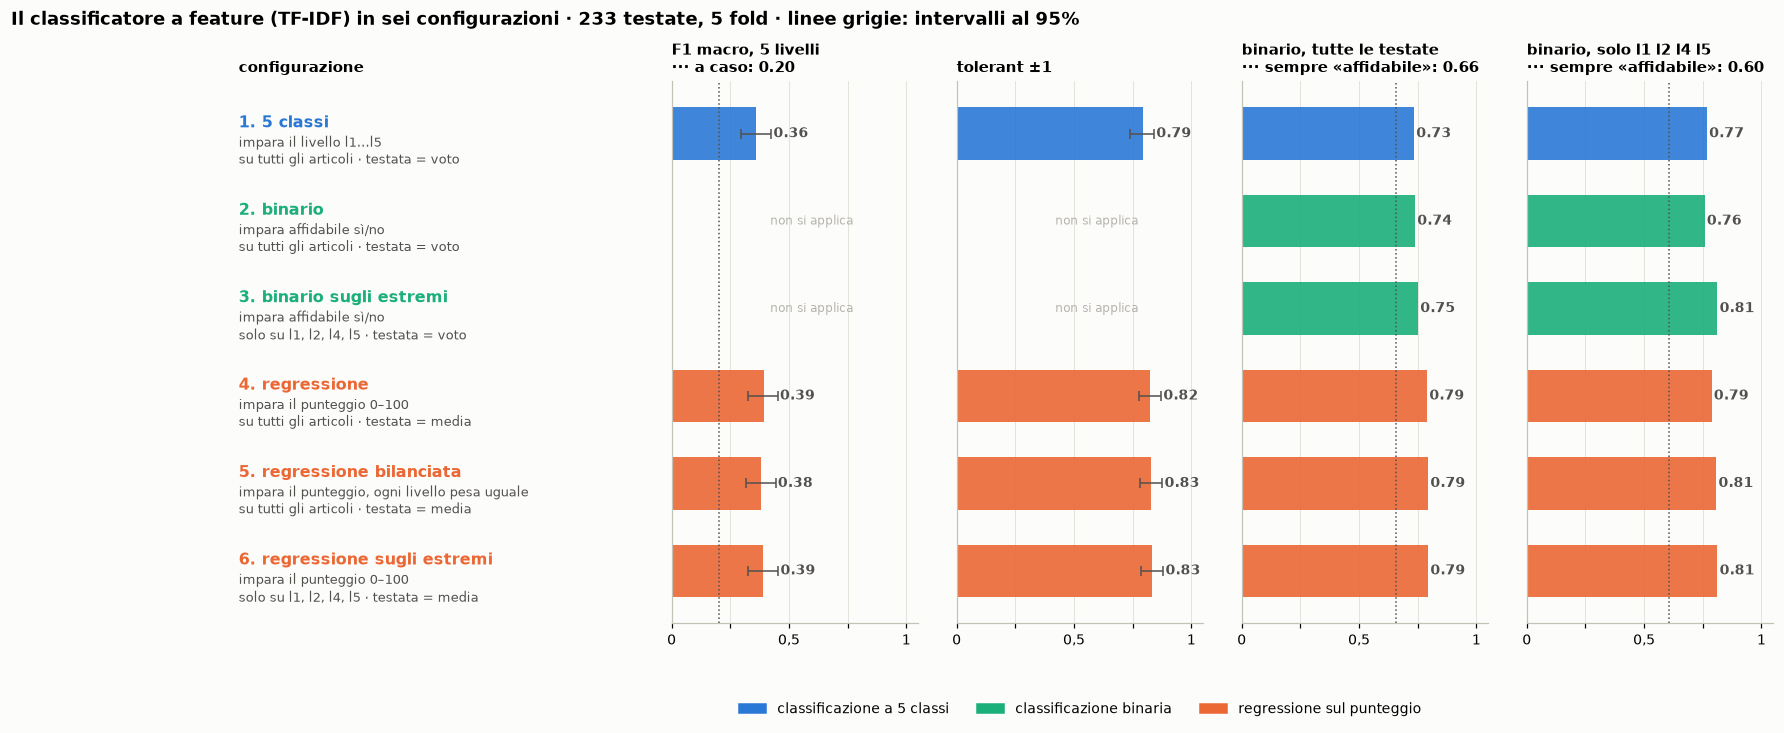

In [5]:
# 4.1 tutte le configurazioni con le loro misure
BLU, VERDE, ARANCIO = "#2a78d6", "#1baf7a", "#eb6834"
FAMIGLIA = {"classificazione a 5 classi": BLU, "classificazione binaria": VERDE, "regressione sul punteggio": ARANCIO}
MODELLI = [  # nome, descrizione, famiglia, riga nella tabella dei 5 livelli, riga nella tabella del binario
    ("1. 5 classi", "impara il livello l1…l5\nsu tutti gli articoli · testata = voto", "classificazione a 5 classi", "1. 5 classi", "1. 5 classi"),
    ("2. binario", "impara affidabile sì/no\nsu tutti gli articoli · testata = voto", "classificazione binaria", None, "2. binario"),
    ("3. binario sugli estremi", "impara affidabile sì/no\nsolo su l1, l2, l4, l5 · testata = voto", "classificazione binaria", None, "3. binario sugli estremi"),
    ("4. regressione", "impara il punteggio 0–100\nsu tutti gli articoli · testata = media", "regressione sul punteggio",
     "4. regressione → quote del training", "4. regressione (≥ 60)"),
    ("5. regressione bilanciata", "impara il punteggio, ogni livello pesa uguale\nsu tutti gli articoli · testata = media",
     "regressione sul punteggio", "5. regressione bilanciata → quote del training", "5. regressione bilanciata (≥ 60)"),
    ("6. regressione sugli estremi", "impara il punteggio 0–100\nsolo su l1, l2, l4, l5 · testata = media", "regressione sul punteggio",
     "6. regressione sugli estremi → quote del training", "6. regressione sugli estremi (≥ 60)")]
ic = lambda testo: [float(x) for x in testo.strip("[]").split(";")]
METRICHE = [("F1 macro, 5 livelli", lambda m: (tab5.loc[m[3], "F1 macro"], ic(tab5.loc[m[3], "F1 macro IC"])) if m[3] else None, 0.2, "a caso"),
            ("tolerant ±1", lambda m: (tab5.loc[m[3], "tolerant ±1"], ic(tab5.loc[m[3], "tolerant ±1 IC"])) if m[3] else None, None, None),
            ("binario, tutte le testate", lambda m: (tab2.loc[m[4], "tutte: accuratezza"], None), vero.mean(), "sempre «affidabile»"),
            ("binario, solo l1 l2 l4 l5", lambda m: (tab2.loc[m[4], "solo estreme: accuratezza"], None), vero[estreme].mean(), "sempre «affidabile»")]

fig = plt.figure(figsize=(18, 6.4))
griglia = fig.add_gridspec(1, 5, width_ratios=[1.6, 1, 1, 1, 1], wspace=0.14)
y = np.arange(len(MODELLI))[::-1]
testo = fig.add_subplot(griglia[0]); testo.axis("off"); testo.set_ylim(-0.6, len(MODELLI) - 0.4)
for yy, (nome, descrizione, famiglia, _, _) in zip(y, MODELLI):
    testo.text(0, yy + 0.12, nome, fontsize=10.5, fontweight="bold", va="center", color=FAMIGLIA[famiglia])
    testo.text(0, yy - 0.2, descrizione, fontsize=8.5, va="center", color=GRIGIO, linespacing=1.3)
testo.set_title("configurazione", loc="left")
for j, (titolo, valore, riferimento, nome_rif) in enumerate(METRICHE, 1):
    ax = fig.add_subplot(griglia[j], sharey=testo)
    for yy, m in zip(y, MODELLI):
        v = valore(m)
        if v is None:
            ax.text(0.42, yy, "non si applica", va="center", fontsize=8, color=CHIARO); continue
        ax.barh(yy, v[0], height=0.6, color=FAMIGLIA[m[2]], alpha=0.9)
        if v[1]:
            ax.errorbar(v[0], yy, xerr=[[v[0] - v[1][0]], [v[1][1] - v[0]]], color=GRIGIO, lw=1, capsize=3)
        ax.text((v[1][1] if v[1] else v[0]) + 0.01, yy, f"{v[0]:.2f}", va="center", fontsize=9, fontweight="bold", color=GRIGIO)
    if riferimento is not None:
        ax.axvline(riferimento, color=GRIGIO, ls=":", lw=1)
        titolo += f"\n··· {nome_rif}: {riferimento:.2f}"
    ax.set_xlim(0, 1.05); ax.set_xticks([0, 0.25, 0.5, 0.75, 1]); ax.set_xticklabels(["0", "", "0,5", "", "1"])
    ax.set_title(titolo, loc="left", fontsize=9.5); ax.tick_params(left=False, labelleft=False)
    ax.grid(False); ax.grid(axis="x")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMIGLIA.values()], FAMIGLIA.keys(), ncol=3, loc="lower center",
           bbox_to_anchor=(0.55, -0.04), fontsize=9)
fig.suptitle("Il classificatore a feature (TF-IDF) in sei configurazioni · 233 testate, 5 fold · linee grigie: intervalli al 95%",
             fontsize=12, fontweight="bold", x=0.01, ha="left")
plt.savefig(GRAFICI / "riassunto.png", dpi=180, bbox_inches="tight"); plt.show()

## 5. In breve

- **5 livelli**: regressione (0,38–0,39) e classificazione a 5 classi (0,36) si equivalgono; sulla tolerant la
  regressione è un po' meglio (0,82–0,83 contro 0,79).
- **Binario**: la regressione con la soglia a 60 è la migliore (0,79 su tutte le testate, fino a 0,81 sulle estreme).
- **Togliere i livelli di mezzo dall'addestramento non costa nulla**: la regressione sugli estremi vale quanto le altre.
- **Per i prossimi modelli** (embedding, ModernBERT): regressione sul punteggio.